# ANSR Traffic Accidents — Data Exploration

## Introduction

This notebook performs a non-destructive initial audit of the ANSR annual workbooks (2010–2024). It treats the four logical datasets separately because they have different granularities:

- **Accidents**: accident-level records.
- **Drivers**: driver/vehicle-related records.
- **Passengers**: passenger-level records.
- **Pedestrians**: pedestrian-level records.

The audit covers workbook and sheet discovery, header detection, dimensions, schema consistency, data types, missing values, exact duplicate rows, accident-ID relationships, and temporal coverage. Original Excel files are never modified.


## Environment setup

This notebook uses `python-calamine` through Pandas to read `.xls`, `.xlsx`, and `.xlsb` files consistently.

Install once in the notebook environment and restart the kernel:

```python
%pip install --upgrade "pandas>=2.2" python-calamine
```


In [28]:
from pathlib import Path
import importlib.util
import re
import unicodedata
import traceback
import warnings
from packaging.version import Version
from collections import defaultdict

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=UserWarning)

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
START_YEAR, END_YEAR = 2010, 2024
EXPECTED_DATASETS = {"Accidents", "Drivers", "Passengers", "Pedestrians"}
SUPPORTED_EXTENSIONS = {".xls", ".xlsx", ".xlsb"}

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid")

if not RAW_DATA_DIR.exists():
    raise FileNotFoundError(
        f"Could not find {RAW_DATA_DIR}. Run from the project root or notebooks/."
    )

CALAMINE_AVAILABLE = (
    importlib.util.find_spec("python_calamine") is not None
    and Version(pd.__version__) >= Version("2.2.0")
)
print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data directory: {RAW_DATA_DIR}")
print(f"Pandas: {pd.__version__}")
print(f"python-calamine available: {CALAMINE_AVAILABLE}")


Project root: /Users/tiagoneves/Desktop/4º ANO/IAA/Projeto/IAA-car-crash-project
Raw data directory: /Users/tiagoneves/Desktop/4º ANO/IAA/Projeto/IAA-car-crash-project/data/raw
Pandas: 3.1.1
python-calamine available: True


In [29]:
dependency_status = pd.DataFrame([
    {"Package": "pandas", "Installed": True, "Version": pd.__version__, "Required": ">= 2.2"},
    {
        "Package": "python-calamine",
        "Installed": importlib.util.find_spec("python_calamine") is not None,
        "Version": "available" if importlib.util.find_spec("python_calamine") else "missing",
        "Required": "Required for .xls, .xlsx and .xlsb"
    }
])
display(dependency_status)

if not CALAMINE_AVAILABLE:
    raise ImportError(
        "Install the required reader, restart the kernel, and run all cells: "
        "%pip install --upgrade 'pandas>=2.2' python-calamine"
    )


,Package,Installed,Version,Required
0,pandas,True,3.1.1,>= 2.2
1,python-calamine,True,available,"Required for .xls, .xlsx and .xlsb"


In [30]:
workbooks = sorted(
    [
        file for file in RAW_DATA_DIR.iterdir()
        if file.is_file() and file.suffix.lower() in SUPPORTED_EXTENSIONS
    ],
    key=lambda file: file.name
)

file_inventory = []

for file in workbooks:
    year_match = re.search(r"(20\d{2})", file.stem)

    file_inventory.append({
        "File": file.name,
        "Year": int(year_match.group(1)) if year_match else None,
        "Format": file.suffix.lower(),
        "Size (MB)": round(file.stat().st_size / (1024 ** 2), 2)
    })

files_df = pd.DataFrame(file_inventory)

display(files_df)

print(f"Total workbooks found: {len(workbooks)}")
print(f"Expected workbooks: {END_YEAR - START_YEAR + 1}")

if len(workbooks) != END_YEAR - START_YEAR + 1:
    warnings.warn(
        f"Expected {END_YEAR - START_YEAR + 1} workbooks, but found {len(workbooks)}."
    )


,File,Year,Format,Size (MB)
0,ISCTE_2010.xls,2010,.xls,91.41
1,ISCTE_2011.xls,2011,.xls,83.22
2,ISCTE_2012.xls,2012,.xls,76.51
3,ISCTE_2013.xls,2013,.xls,78.21
4,ISCTE_2014.xls,2014,.xls,79.21
5,ISCTE_2015.xls,2015,.xls,83.18
6,ISCTE_2016.xls,2016,.xls,84.39
7,ISCTE_2017.xls,2017,.xls,90.39
8,ISCTE_2018.xls,2018,.xls,89.24
9,ISCTE_2019.xls,2019,.xls,93.37


Total workbooks found: 15
Expected workbooks: 15


In [31]:
expected_years = set(range(START_YEAR, END_YEAR + 1))

available_years = {
    item["Year"]
    for item in file_inventory
    if item["Year"] is not None
}

missing_years = sorted(expected_years - available_years)
unexpected_years = sorted(available_years - expected_years)

print("Missing years:", missing_years or "None")
print("Unexpected years:", unexpected_years or "None")

print("\nFile formats:")
display(files_df["Format"].value_counts().to_frame("Number of files"))

Missing years: None
Unexpected years: None

File formats:


,Number of files
Format,
.xls,11
.xlsx,2
.xlsb,2


In [32]:
def get_excel_engine(file):
    """Use python-calamine for all supported Excel formats."""
    if file.suffix.lower() not in SUPPORTED_EXTENSIONS:
        raise ValueError(f"Unsupported Excel format: {file.suffix}")
    if not CALAMINE_AVAILABLE:
        raise ImportError("python-calamine is required; see Environment setup.")
    return "calamine"


def normalize_label(value):
    value = unicodedata.normalize("NFKD", str(value))
    value = "".join(ch for ch in value if not unicodedata.combining(ch))
    return re.sub(r"[^a-z0-9]", "", value.lower())


def normalize_sheet_name(name):
    return normalize_label(name)


def identify_dataset(sheet_name):
    """Map historical sheet labels to the four logical datasets."""
    name = normalize_sheet_name(sheet_name)
    if "peao" in name or "peoes" in name:
        return "Pedestrians"
    if "passag" in name or "psg" in name:
        return "Passengers"
    if "cond" in name:
        return "Drivers"
    if "acident" in name or "30diasacv" in name:
        return "Accidents"
    return "Unknown"


sheet_inventory, read_errors = [], []

for file in workbooks:
    match = re.search(r"(20\d{2})", file.stem)
    year = int(match.group(1)) if match else None
    try:
        engine = get_excel_engine(file)
        with pd.ExcelFile(file, engine=engine) as excel:
            for sheet in excel.sheet_names:
                dataset = identify_dataset(sheet)
                sheet_inventory.append({
                    "Year": year, "File": file.name, "Sheet": sheet,
                    "Dataset": dataset, "Expected": dataset in EXPECTED_DATASETS,
                    "Engine": engine
                })
    except Exception as error:
        read_errors.append({
            "File": file.name, "Year": year,
            "Error type": type(error).__name__, "Error": repr(error),
            "Traceback": traceback.format_exc()
        })

sheets_df = pd.DataFrame(
    sheet_inventory,
    columns=["Year", "File", "Sheet", "Dataset", "Expected", "Engine"]
)
errors_df = pd.DataFrame(read_errors)

success_count = sheets_df["File"].nunique() if not sheets_df.empty else 0
print(f"Successfully inspected: {success_count} of {len(workbooks)} workbooks.")
display(sheets_df)
if not errors_df.empty:
    display(errors_df[["File", "Year", "Error type", "Error"]])


Successfully inspected: 15 of 15 workbooks.


,Year,File,Sheet,Dataset,Expected,Engine
0,2010,ISCTE_2010.xls,30 Dias_Cond_Veic,Drivers,True,calamine
1,2010,ISCTE_2010.xls,30 Dias_Passag,Passengers,True,calamine
2,2010,ISCTE_2010.xls,30 Dias _ Acidentes,Accidents,True,calamine
3,2010,ISCTE_2010.xls,30 Dias_Peões,Pedestrians,True,calamine
4,2011,ISCTE_2011.xls,30 Dias_Cond_Veic,Drivers,True,calamine
5,2011,ISCTE_2011.xls,30 Dias_Passag,Passengers,True,calamine
6,2011,ISCTE_2011.xls,30 Dias _ Acidentes,Accidents,True,calamine
7,2011,ISCTE_2011.xls,30 Dias_Peões,Pedestrians,True,calamine
8,2012,ISCTE_2012.xls,30 Dias_Cond_Veic,Drivers,True,calamine
9,2012,ISCTE_2012.xls,30 Dias_Passag,Passengers,True,calamine


In [33]:
if sheets_df.empty:
    print("No sheets were discovered. Check the workbook-reading errors.")
else:
    sheet_coverage = (
        sheets_df.pivot_table(
            index="Year", columns="Sheet", values="File",
            aggfunc="count", fill_value=0
        ).sort_index()
    )
    print("Original sheet names found in each year:")
    display(sheet_coverage)

    dataset_coverage = (
        sheets_df[sheets_df["Dataset"] != "Unknown"]
        .pivot_table(
            index="Year", columns="Dataset", values="File",
            aggfunc="count", fill_value=0
        )
        .reindex(columns=sorted(EXPECTED_DATASETS), fill_value=0)
        .sort_index()
    )
    print("Canonical dataset coverage by year:")
    display(dataset_coverage)

    coverage_issues_df = pd.DataFrame([
        {
            "Year": year,
            "Missing datasets": ", ".join(
                sorted(EXPECTED_DATASETS - {
                    dataset for dataset, count in dataset_coverage.loc[year].items()
                    if count > 0
                })
            ) or "None"
        }
        for year in sorted(available_years)
    ])
    display(coverage_issues_df)

    unknown_sheets = sheets_df[sheets_df["Dataset"] == "Unknown"]
    if not unknown_sheets.empty:
        print("Unrecognized sheet labels:")
        display(unknown_sheets[["Year", "File", "Sheet"]])


Original sheet names found in each year:


Sheet,30 Dias _ Acidentes,30 Dias_Cond_Veic,30 Dias_Cond_veículos,30 Dias_Passag,30 Dias_Peões,30dias_acV,30dias_cond,30dias_peao,30dias_psg,Acidentes
Year,,,,,,,,,,
2010,1,1,0,1,1,0,0,0,0,0
2011,1,1,0,1,1,0,0,0,0,0
2012,1,1,0,1,1,0,0,0,0,0
2013,1,1,0,1,1,0,0,0,0,0
2014,1,1,0,1,1,0,0,0,0,0
2015,1,1,0,1,1,0,0,0,0,0
2016,1,1,0,1,1,0,0,0,0,0
2017,1,1,0,1,1,0,0,0,0,0
2018,1,1,0,1,1,0,0,0,0,0


Canonical dataset coverage by year:


Dataset,Accidents,Drivers,Passengers,Pedestrians
Year,,,,
2010,1,1,1,1
2011,1,1,1,1
2012,1,1,1,1
2013,1,1,1,1
2014,1,1,1,1
2015,1,1,1,1
2016,1,1,1,1
2017,1,1,1,1
2018,1,1,1,1


,Year,Missing datasets
0,2010,None
1,2011,None
2,2012,None
3,2013,None
4,2014,None
5,2015,None
6,2016,None
7,2017,None
8,2018,None
9,2019,None


## 7. Dataset Content Inspection

The inventory confirms sheet availability, but not the structure or quality of the contents. Excel files may contain title or blank rows before the column headers. The reader below locates the header by searching for `Id. Acidente`, rather than assuming a fixed row.

Only completely empty columns and rows are removed from the in-memory copy. No source workbook is changed, and no missing values are imputed.

In [34]:
def find_header_row(preview, max_rows=25):
    """Find the header row containing the Accident ID column."""
    for row_idx in range(min(max_rows, len(preview))):
        labels = [normalize_label(value) for value in preview.iloc[row_idx].tolist()]
        if any(label in {"idacidente", "accidentid"} for label in labels):
            return row_idx
    raise ValueError("Header row not found: 'Id. Acidente' was not detected.")


def make_unique_columns(columns):
    """Preserve labels while assigning unique names to duplicate/blank columns."""
    seen, result = {}, []
    for idx, value in enumerate(columns):
        label = str(value).strip() if pd.notna(value) else ""
        if not label or label.lower().startswith("unnamed:"):
            label = f"unnamed_column_{idx}"
        count = seen.get(label, 0)
        seen[label] = count + 1
        result.append(label if count == 0 else f"{label}__{count}")
    return result


def read_annual_sheet(file_path, sheet_name):
    """Read a sheet with Calamine and detect its header row automatically."""
    preview = pd.read_excel(
        file_path, sheet_name=sheet_name, engine="calamine",
        header=None, nrows=25
    )
    header_row = find_header_row(preview)
    df = pd.read_excel(
        file_path, sheet_name=sheet_name, engine="calamine",
        header=header_row
    )
    df.columns = make_unique_columns(df.columns)
    df = df.dropna(axis=1, how="all").dropna(axis=0, how="all").reset_index(drop=True)
    return df, header_row


print("Header detection and reusable sheet reader are ready.")

def normalize_accident_id(value):
    """Convert IDs to comparable strings without losing alphanumeric identifiers."""
    if pd.isna(value):
        return None
    if isinstance(value, (int, np.integer)):
        return str(int(value))
    if isinstance(value, (float, np.floating)) and np.isfinite(value) and float(value).is_integer():
        return str(int(value))

    value = str(value).strip()
    if not value:
        return None
    # Excel may expose integer identifiers as strings ending in '.0'.
    if re.fullmatch(r"\d+\.0", value):
        value = value[:-2]
    return value


Header detection and reusable sheet reader are ready.


## 8. Dataset Dimensions and Schema Consistency

Each annual sheet is read separately, summarized, and released from memory. This avoids keeping all 60 annual tables in memory simultaneously.

Schema differences are reported, not automatically treated as errors: they may reflect changes in ANSR data collection over time.

In [35]:
dimension_records = []
schema_records = []
dtype_records = []
missing_records = []
duplicate_records = []
relationship_records = []
temporal_records = []
content_read_errors = []
accident_ids_by_year = {}
participant_ids_by_year = defaultdict(dict)

for _, sheet_row in sheets_df.iterrows():
    dataset = sheet_row["Dataset"]
    if dataset not in EXPECTED_DATASETS:
        continue

    year = sheet_row["Year"]
    file_path = RAW_DATA_DIR / sheet_row["File"]

    try:
        df, header_row = read_annual_sheet(file_path, sheet_row["Sheet"])

        dimension_records.append({
            "Year": year, "Dataset": dataset, "Sheet": sheet_row["Sheet"],
            "Rows": len(df), "Columns": len(df.columns),
            "Header row (0-based)": header_row
        })

        for col in df.columns:
            schema_records.append({
                "Year": year, "Dataset": dataset, "Column": col,
                "Normalized column": normalize_label(col)
            })
            dtype_records.append({
                "Year": year, "Dataset": dataset,
                "Column": col, "Dtype": str(df[col].dtype)
            })
            missing = int(df[col].isna().sum())
            missing_records.append({
                "Year": year, "Dataset": dataset, "Column": col,
                "Missing": missing, "Total": len(df),
                "Missing (%)": round(100 * missing / len(df), 2) if len(df) else np.nan
            })

        duplicate_count = int(df.duplicated().sum())
        duplicate_records.append({
            "Year": year, "Dataset": dataset, "Rows": len(df),
            "Exact duplicate rows": duplicate_count,
            "Duplicate (%)": round(100 * duplicate_count / len(df), 2) if len(df) else 0.0
        })

        id_col = next(
            (col for col in df.columns
             if normalize_label(col) in {"idacidente", "accidentid"}),
            None
        )
        if id_col is not None:
            ids = df[id_col].map(normalize_accident_id).dropna()
            if dataset == "Accidents":
                accident_ids_by_year[year] = set(ids.tolist())
            else:
                participant_ids_by_year[year][dataset] = set(ids.tolist())
            relationship_records.append({
                "Year": year, "Dataset": dataset,
                "Rows with Accident ID": int(ids.size),
                "Distinct Accident IDs": int(ids.nunique()),
                "Missing Accident IDs": int(df[id_col].isna().sum())
            })
        else:
            relationship_records.append({
                "Year": year, "Dataset": dataset,
                "Rows with Accident ID": np.nan,
                "Distinct Accident IDs": np.nan,
                "Missing Accident IDs": np.nan
            })

        date_col = next(
            (col for col in df.columns
             if normalize_label(col) in {"datahora", "datetime", "date"}),
            None
        )
        if date_col is not None:
            raw_dates = df[date_col].astype("string").str.strip()
            normalized_dates = raw_dates.str.replace(
                r"^(\d{4}):(\d{2}):(\d{2})",
                r"\1-\2-\3",
                regex=True
            )
            parsed = pd.to_datetime(normalized_dates, errors="coerce", format="mixed", dayfirst=True)
            valid = parsed.dropna()
            temporal_records.append({
                "Year": year, "Dataset": dataset, "Date column": date_col,
                "Valid dates": int(valid.size),
                "Unparsed dates": int(parsed.isna().sum()),
                "Minimum date": valid.min() if not valid.empty else pd.NaT,
                "Maximum date": valid.max() if not valid.empty else pd.NaT
            })

    except Exception as error:
        content_read_errors.append({
            "Year": year, "File": file_path.name, "Sheet": sheet_row["Sheet"],
            "Dataset": dataset, "Error type": type(error).__name__,
            "Error": repr(error), "Traceback": traceback.format_exc()
        })

dimensions_df = pd.DataFrame(dimension_records)
schema_df = pd.DataFrame(schema_records)
column_types_df = pd.DataFrame(dtype_records)
missing_values_df = pd.DataFrame(missing_records)
duplicates_df = pd.DataFrame(duplicate_records)
relationship_counts_df = pd.DataFrame(relationship_records)
temporal_df = pd.DataFrame(temporal_records)
content_read_errors_df = pd.DataFrame(content_read_errors)

print(f"Dataset sheets audited: {len(dimensions_df)}")
print(f"Dataset-sheet read failures: {len(content_read_errors_df)}")
display(dimensions_df.sort_values(["Dataset", "Year"]) if not dimensions_df.empty else dimensions_df)
if not content_read_errors_df.empty:
    display(content_read_errors_df[["Year", "File", "Sheet", "Error type", "Error"]])

Dataset sheets audited: 60
Dataset-sheet read failures: 0


,Year,Dataset,Sheet,Rows,Columns,Header row (0-based)
2,2010,Accidents,30 Dias _ Acidentes,35426,43,2
6,2011,Accidents,30 Dias _ Acidentes,32541,43,2
10,2012,Accidents,30 Dias _ Acidentes,29867,43,2
14,2013,Accidents,30 Dias _ Acidentes,30339,43,2
18,2014,Accidents,30 Dias _ Acidentes,30604,43,2
22,2015,Accidents,30 Dias _ Acidentes,31953,43,2
26,2016,Accidents,30 Dias _ Acidentes,32299,43,2
30,2017,Accidents,30 Dias _ Acidentes,34416,43,2
34,2018,Accidents,30 Dias _ Acidentes,34235,43,2
38,2019,Accidents,30 Dias _ Acidentes,35704,43,2


## 9. Schema Comparison Across Years

The schema audit compares variables independently for each logical dataset. Column labels are normalized for comparison (case, accents, spaces, and punctuation are ignored), while the original labels remain visible.

A variable absent in a year is a finding to investigate, not an automatic reason to discard that year or variable.

In [36]:
schema_comparison_records = []

if not schema_df.empty:
    for dataset in sorted(EXPECTED_DATASETS):
        subset = schema_df[schema_df["Dataset"] == dataset]
        years_with_dataset = sorted(subset["Year"].dropna().unique())
        for normalized_name, group in subset.groupby("Normalized column"):
            years_present = sorted(group["Year"].dropna().unique())
            original_labels = sorted(group["Column"].dropna().astype(str).unique())
            schema_comparison_records.append({
                "Dataset": dataset,
                "Normalized column": normalized_name,
                "Original column labels": " | ".join(original_labels),
                "Years present": len(years_present),
                "Years with dataset": len(years_with_dataset),
                "Present in all observed years": len(years_present) == len(years_with_dataset),
                "Missing years": ", ".join(
                    str(y) for y in sorted(set(years_with_dataset) - set(years_present))
                ) or "None"
            })

schema_comparison_df = pd.DataFrame(schema_comparison_records)
display(
    schema_comparison_df.sort_values(
        ["Dataset", "Present in all observed years", "Normalized column"]
    ) if not schema_comparison_df.empty else schema_comparison_df
)

,Dataset,Normalized column,Original column labels,Years present,Years with dataset,Present in all observed years,Missing years
0,Accidents,ano,Ano,1,15,False,"2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2024"
6,Accidents,descesquema,Desc. Esquema,1,15,False,"2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2024"
11,Accidents,estadoconservacao,Estado Conservação,14,15,False,2024
13,Accidents,fga30dias,FG a 30 dias,2,15,False,"2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2023, 2024"
14,Accidents,fla30dias,FL a 30 dias,2,15,False,"2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2023, 2024"
...,...,...,...,...,...,...,...
165,Pedestrians,accoespeao,Acções Peão,15,15,True,None
171,Pedestrians,idacidente,Id. Acidente,15,15,True,None
172,Pedestrians,idpeao,Id. Peao,15,15,True,None
173,Pedestrians,lesoesa30dias,Lesões a 30 dias,15,15,True,None


## 10. Data Types, Missing Values, and Duplicates

Missing-value rates are calculated per variable, year, and dataset. No imputation is performed.

Exact duplicate rows are counted within each annual sheet. Repeated `Id. Acidente` values in participant datasets are expected because an accident can involve multiple people; they are not, by themselves, duplicate records.

In [41]:
print("Accident ID counts:")
display(
    relationship_counts_df.sort_values(["Year", "Dataset"])
    if not relationship_counts_df.empty else relationship_counts_df
)

referential_records = []
for year, participant_datasets in sorted(participant_ids_by_year.items()):
    for dataset, participant_ids in sorted(participant_datasets.items()):
        if year not in accident_ids_by_year:
            referential_records.append({
                "Year": year, "Dataset": dataset,
                "Distinct participant Accident IDs": len(participant_ids),
                "Unmatched IDs": np.nan, "Unmatched (%)": np.nan,
                "Status": "Accident ID set unavailable"
            })
            continue

        unmatched = participant_ids - accident_ids_by_year[year]
        referential_records.append({
            "Year": year, "Dataset": dataset,
            "Distinct participant Accident IDs": len(participant_ids),
            "Unmatched IDs": len(unmatched),
            "Unmatched (%)": round(100 * len(unmatched) / len(participant_ids), 2)
                if participant_ids else 0.0,
            "Status": "OK" if not unmatched else "Review required"
        })

referential_integrity_df = pd.DataFrame(referential_records)
display(referential_integrity_df)

# Display data quality results

print("DATA TYPES")
display(
    column_types_df.sort_values(
        ["Dataset", "Year", "Column"]
    )
)

print("MISSING VALUES")
display(
    missing_values_df.sort_values(
        ["Dataset", "Missing (%)"],
        ascending=[True, False]
    )
)

print("TOP 15 VARIABLES WITH MOST MISSING VALUES")
display(
    missing_values_df
    .sort_values("Missing (%)", ascending=False)
    .groupby("Dataset")
    .head(15)
)

print("DUPLICATE RECORDS")
display(
    duplicates_df.sort_values(
        ["Dataset", "Year"]
    )
)


Accident ID counts:


,Year,Dataset,Rows with Accident ID,Distinct Accident IDs,Missing Accident IDs
2,2010,Accidents,35426,35426,0
0,2010,Drivers,53681,33622,0
1,2010,Passengers,13175,9535,0
3,2010,Pedestrians,5968,5664,0
6,2011,Accidents,32541,32541,0
4,2011,Drivers,48358,30180,0
5,2011,Passengers,11292,8286,0
7,2011,Pedestrians,5832,5501,0
10,2012,Accidents,29867,29867,0
8,2012,Drivers,44715,28042,0


,Year,Dataset,Distinct participant Accident IDs,Unmatched IDs,Unmatched (%),Status
0,2010,Drivers,33622,0,0.0,OK
1,2010,Passengers,9535,0,0.0,OK
2,2010,Pedestrians,5664,0,0.0,OK
3,2011,Drivers,30180,0,0.0,OK
4,2011,Passengers,8286,0,0.0,OK
5,2011,Pedestrians,5501,0,0.0,OK
6,2012,Drivers,28042,0,0.0,OK
7,2012,Passengers,7403,0,0.0,OK
8,2012,Pedestrians,4947,0,0.0,OK
9,2013,Drivers,28712,0,0.0,OK


DATA TYPES


,Year,Dataset,Column,Dtype
82,2010,Accidents,Características Tecnicas1,str
90,2010,Accidents,Cod Via,str
85,2010,Accidents,Concelho,str
83,2010,Accidents,Cond Aderência,str
69,2010,Accidents,Datahora,str
...,...,...,...,...
2084,2024,Pedestrians,Peao Gr.Etario(6-9) SUM,int64
2083,2024,Pedestrians,Peao Gr.Etario(<=5) SUM,int64
2100,2024,Pedestrians,Peao Gr.Etario(Não Def.) SUM,int64
2078,2024,Pedestrians,Sexo,str


MISSING VALUES


,Year,Dataset,Column,Missing,Total,Missing (%)
1856,2023,Accidents,Nome Outra Via,35038,36595,95.75
1988,2024,Accidents,Nome Outra Via,36399,38037,95.69
1999,2024,Accidents,Sentidos,32767,38037,86.15
1220,2018,Accidents,Km,24327,34235,71.06
1079,2017,Accidents,Km,23918,34416,69.50
...,...,...,...,...,...,...
2096,2024,Pedestrians,Peao Gr.Etario (60-64) SUM,0,5407,0.00
2097,2024,Pedestrians,Peao Gr.Etario (65-69) SUM,0,5407,0.00
2098,2024,Pedestrians,Peao Gr.Etario (70-74) SUM,0,5407,0.00
2099,2024,Pedestrians,Peao Gr.Etario (>=75) SUM,0,5407,0.00


TOP 15 VARIABLES WITH MOST MISSING VALUES


,Year,Dataset,Column,Missing,Total,Missing (%)
1856,2023,Accidents,Nome Outra Via,35038,36595,95.75
1988,2024,Accidents,Nome Outra Via,36399,38037,95.69
1999,2024,Accidents,Sentidos,32767,38037,86.15
1220,2018,Accidents,Km,24327,34235,71.06
1857,2023,Accidents,Km,25434,36595,69.50
1079,2017,Accidents,Km,23918,34416,69.50
1716,2022,Accidents,Km,22792,32792,69.50
1989,2024,Accidents,Km,26367,38037,69.32
374,2012,Accidents,Km,20606,29867,68.99
797,2015,Accidents,Km,22033,31953,68.95


DUPLICATE RECORDS


,Year,Dataset,Rows,Exact duplicate rows,Duplicate (%)
2,2010,Accidents,35426,0,0.0
6,2011,Accidents,32541,0,0.0
10,2012,Accidents,29867,0,0.0
14,2013,Accidents,30339,0,0.0
18,2014,Accidents,30604,0,0.0
22,2015,Accidents,31953,0,0.0
26,2016,Accidents,32299,0,0.0
30,2017,Accidents,34416,0,0.0
34,2018,Accidents,34235,0,0.0
38,2019,Accidents,35704,0,0.0


## 11. Accident ID Relationship Checks

The four datasets are related through `Id. Acidente`, but they have different granularities. This notebook does not perform a direct many-to-many merge.

The following check compares participant accident IDs against the accident IDs from the same year. IDs are compared as trimmed strings so alphanumeric identifiers are preserved.

In [38]:
print("Accident ID counts:")
display(
    relationship_counts_df.sort_values(["Year", "Dataset"])
    if not relationship_counts_df.empty else relationship_counts_df
)

referential_records = []
for _, sheet_row in sheets_df.iterrows():
    dataset, year = sheet_row["Dataset"], sheet_row["Year"]
    if dataset not in {"Drivers", "Passengers", "Pedestrians"}:
        continue

    try:
        df, _ = read_annual_sheet(
            RAW_DATA_DIR / sheet_row["File"], sheet_row["Sheet"]
        )
        id_col = next(
            (col for col in df.columns
             if normalize_label(col) in {"idacidente", "accidentid"}),
            None
        )
        if id_col is None:
            continue

        if year not in accident_ids_by_year:
            referential_records.append({
                "Year": year, "Dataset": dataset,
                "Distinct participant Accident IDs": np.nan,
                "Unmatched IDs": np.nan, "Unmatched (%)": np.nan,
                "Status": "Accident ID set unavailable"
            })
            continue

        ids = df[id_col].dropna().astype("string").str.strip()
        participant_ids = set(ids[ids.ne("")].tolist())
        unmatched = participant_ids - accident_ids_by_year[year]

        referential_records.append({
            "Year": year, "Dataset": dataset,
            "Distinct participant Accident IDs": len(participant_ids),
            "Unmatched IDs": len(unmatched),
            "Unmatched (%)": round(100 * len(unmatched) / len(participant_ids), 2)
                if participant_ids else 0.0,
            "Status": "OK" if not unmatched else "Review required"
        })

    except Exception as error:
        referential_records.append({
            "Year": year, "Dataset": dataset,
            "Distinct participant Accident IDs": np.nan,
            "Unmatched IDs": np.nan, "Unmatched (%)": np.nan,
            "Status": f"Read error: {type(error).__name__}"
        })

referential_integrity_df = pd.DataFrame(referential_records)
display(referential_integrity_df)

Accident ID counts:


,Year,Dataset,Rows with Accident ID,Distinct Accident IDs,Missing Accident IDs
2,2010,Accidents,35426,35426,0
0,2010,Drivers,53681,33622,0
1,2010,Passengers,13175,9535,0
3,2010,Pedestrians,5968,5664,0
6,2011,Accidents,32541,32541,0
4,2011,Drivers,48358,30180,0
5,2011,Passengers,11292,8286,0
7,2011,Pedestrians,5832,5501,0
10,2012,Accidents,29867,29867,0
8,2012,Drivers,44715,28042,0


,Year,Dataset,Distinct participant Accident IDs,Unmatched IDs,Unmatched (%),Status
0,2010,Drivers,33622,0,0.0,OK
1,2010,Passengers,9535,0,0.0,OK
2,2010,Pedestrians,5664,0,0.0,OK
3,2011,Drivers,30180,0,0.0,OK
4,2011,Passengers,8286,0,0.0,OK
5,2011,Pedestrians,5501,0,0.0,OK
6,2012,Drivers,28042,0,0.0,OK
7,2012,Passengers,7403,0,0.0,OK
8,2012,Pedestrians,4947,0,0.0,OK
9,2013,Drivers,28712,0,0.0,OK


## 12. Temporal Coverage

Temporal coverage is extracted from `Datahora` where that column exists. The parser supports the ANSR string pattern `YYYY:MM:DD HH:MM:SS` and values directly understood by Pandas.

The accident dataset is the primary source for accident-level temporal analysis. Date fields in participant datasets are reported separately and should not be mistaken for independent accident counts.

,Year,Dataset,Date column,Valid dates,Unparsed dates,Minimum date,Maximum date
2,2010,Accidents,Datahora,35426,0,2010-01-01 00:05:00,2010-12-31 23:45:00
6,2011,Accidents,Datahora,32541,0,2011-01-01 00:01:00,2011-12-31 23:30:00
10,2012,Accidents,Datahora,29867,0,2012-01-01 00:30:00,2012-12-31 23:55:00
14,2013,Accidents,Datahora,30339,0,2013-01-01 01:00:00,2013-12-31 23:30:00
18,2014,Accidents,Datahora,30604,0,2014-01-01 00:05:00,2014-12-31 20:30:00
22,2015,Accidents,Datahora,31953,0,2015-01-01 00:01:00,2015-12-31 23:30:00
26,2016,Accidents,Datahora,32299,0,2016-01-01 00:00:00,2016-12-31 23:30:00
30,2017,Accidents,Datahora,34416,0,2017-01-01 00:00:00,2017-12-31 23:50:00
34,2018,Accidents,Datahora,34235,0,2018-01-01 00:02:00,2018-12-31 23:55:00
38,2019,Accidents,Datahora,35704,0,2019-01-01 00:03:00,2019-12-31 23:40:00


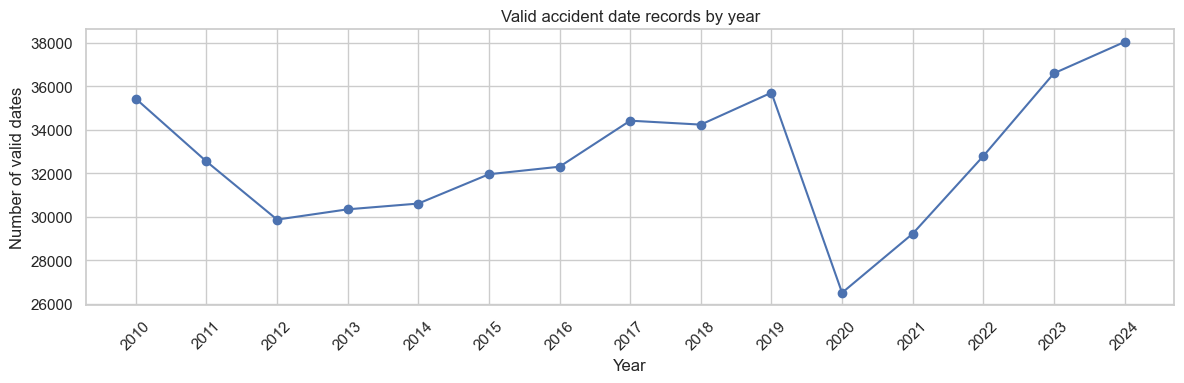

In [39]:
if not temporal_df.empty:
    display(temporal_df.sort_values(["Dataset", "Year"]))

    accident_dates = temporal_df[
        temporal_df["Dataset"] == "Accidents"
    ].dropna(subset=["Valid dates"])

    if not accident_dates.empty:
        plt.figure(figsize=(12, 4))
        plt.plot(
            accident_dates["Year"], accident_dates["Valid dates"],
            marker="o"
        )
        plt.title("Valid accident date records by year")
        plt.xlabel("Year")
        plt.ylabel("Number of valid dates")
        plt.xticks(accident_dates["Year"], rotation=45)
        plt.tight_layout()
        plt.show()
else:
    print("No usable Datahora columns were found.")

## 13. Initial Findings and Audit Status

Use the generated tables to record evidence-based findings. In particular:

- A sheet being present does not prove its contents are complete.
- Schema differences may reflect changes in data collection.
- High missingness does not automatically justify dropping a variable.
- Repeated accident IDs in participant tables are normal.
- Unmatched accident IDs, if any, require investigation.
- No imputation, feature engineering, clustering, or supervised learning is performed in this notebook.

The next CRISP-DM step will use these findings to plan data preparation.

In [40]:
audit_status_df = pd.DataFrame([
    {"Check": "Annual workbooks discovered", "Result": len(workbooks)},
    {"Check": "Annual workbooks expected", "Result": END_YEAR - START_YEAR + 1},
    {"Check": "Workbooks with sheet inventory", "Result": sheets_df["File"].nunique() if not sheets_df.empty else 0},
    {"Check": "Expected logical datasets", "Result": len(EXPECTED_DATASETS)},
    {"Check": "Dataset sheets successfully audited", "Result": len(dimensions_df)},
    {"Check": "Dataset-sheet read failures", "Result": len(content_read_errors_df)},
    {"Check": "Years missing from filenames", "Result": len(missing_years)}
])
display(audit_status_df)

print(
    "Initial data audit finished. Review the generated tables before "
    "making data-preparation decisions."
)

,Check,Result
0,Annual workbooks discovered,15
1,Annual workbooks expected,15
2,Workbooks with sheet inventory,15
3,Expected logical datasets,4
4,Dataset sheets successfully audited,60
5,Dataset-sheet read failures,0
6,Years missing from filenames,0


Initial data audit finished. Review the generated tables before making data-preparation decisions.


## Reproducibility and Data Handling

- Run from the repository root or the `notebooks/` directory.
- Keep the original ANSR files in `data/raw/`.
- Do not commit restricted raw/interim/processed data to a public repository.
- The notebook reads each sheet for analysis and does not write to source workbooks.
- If a workbook fails, inspect `content_read_errors_df` and its traceback before attempting conversion or repair.